In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nest
import pynestml
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

print("NEST  :", nest.__version__)
print("NESTML:", pynestml.__version__)

# Legge il modello NESTML
with open("mntb_hh_kv3_neuron.nestml", "r") as f:
    model_source = f.read()

# Genera e compila il modulo
wt_module, wt_model = NESTCodeGeneratorUtils.generate_code_for(model_source)

print("Modulo generato:", wt_module)
print("Nome modello:", wt_model)

# Carica il modulo in NEST
nest.ResetKernel()
nest.Install(wt_module)

# Verifica che il modello sia effettivamente disponibile
models = nest.Models()
print("Modello disponibile:", wt_model in models)

# Crea un neurone di prova solo se il modello è stato caricato
assert wt_model in models, "Il modello non risulta caricato in NEST!"

neuron = nest.Create(wt_model, 1)
print(neuron.get())


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Nov  4 2025 17:52:39

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

NEST  : 3.9.0
NESTML: 8.2.0



              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Nov  4 2025 17:52:39

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



Float.__new__() missing 1 required positional argument: 'num'
Modulo generato: nestml_57233ee08c6948bda14acd9ba89d6131_module
Nome modello: mntb_hh_kv3_neuron_nestml

Nov 20 10:35:48 Install [Info]: 
    loaded module nestml_57233ee08c6948bda14acd9ba89d6131_module
Modello disponibile: True
{'Act_m': 0.061810591868597935, 'Act_n': 0.09623312821932044, 'beta_Ca': 0.001, 'C_m': 10.0, 'Ca': 0.0, 'E_K': -80.0, 'E_L': -63.0, 'E_Na': 50.0, 'element_type': 'neuron', 'frozen': False, 'g_Kv3': 150.0, 'g_L': 2.0, 'g_Na': 500.0, 'global_id': 1, 'I_e': 0.0, 'Inact_h': 0.6547427917566268, 'Inact_p': 0.9999637976310677, 'local': True, 'model': 'mntb_hh_kv3_neuron_nestml', 'model_id': 106, 'node_uses_wfr': False, 'recordables': ('Act_m', 'Act_n', 'Inact_h', 'Inact_p', 'V_m', 'V_m_old', 'refr_t', 'Act_l', 'Inact_r', 'K_syn_exc__X__exc_spikes', 'K_syn_exc__X__exc_spikes__d', 'K_syn_inh__X__inh_spikes', 'K_syn_inh__X__inh_spikes__d'), 'synaptic_elements': {}, 'tau_Ca': 10000.0, 'thread': 0, 'thread_local

/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/ebrains-25-10/.spack-env/view/lib/python3.11/site-packages/nest/lib/hl_api_helper.py:114: UserWarning:
Models is deprecated and will be removed in a future version of NEST.
Please use nest.node_models or nest.synapse_models instead!



Running A1 at 100 Hz...

Nov 19 12:28:54 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.01 ms.

Nov 19 12:28:54 Install [Info]: 
    loaded module nestml_e35a44de6d6040ad904717fa6e570e0b_module

Nov 19 12:28:54 NodeManager::prepare_nodes [Info]: 
    Preparing 3 nodes for simulation.

Nov 19 12:28:54 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 3
    Simulation time (ms): 320
    Number of OpenMP threads: 1
    Number of MPI processes: 1

Nov 19 12:28:55 SimulationManager::run [Info]: 
    Simulation finished.
Successful responses: 30/30
Failures: 0/30

Running A1 at 300 Hz...

Nov 19 12:28:55 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.01 ms.

Nov 19 12:28:55 Install [Info]: 
    loaded module nestml_e35a44de6d6040ad904717fa6e570e0b_module

Nov 19 12:28:55 NodeManager::prepare_nodes [Info]: 
    Preparing 3 nodes for simulation.

Nov 19 12:28:55 SimulationManager::start_updating_ 

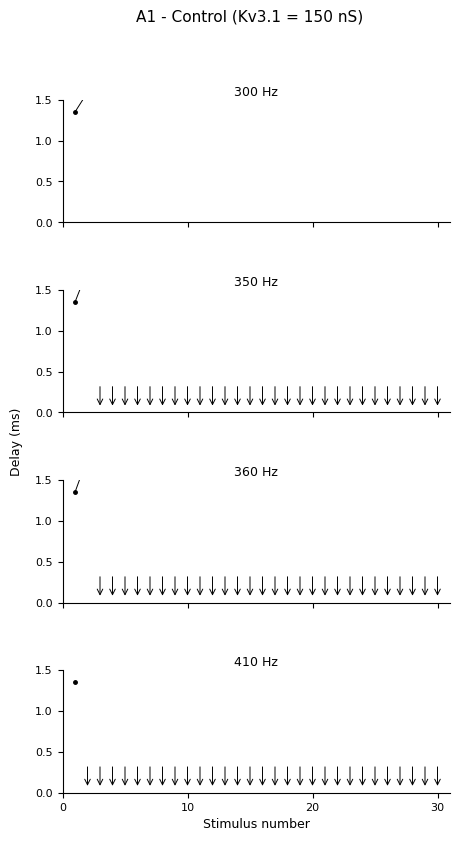

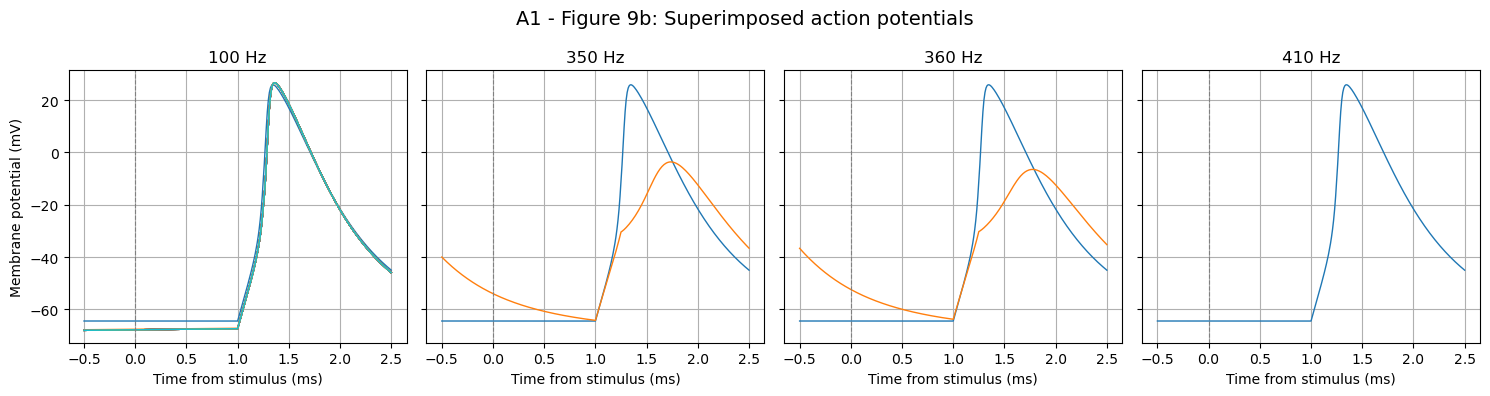

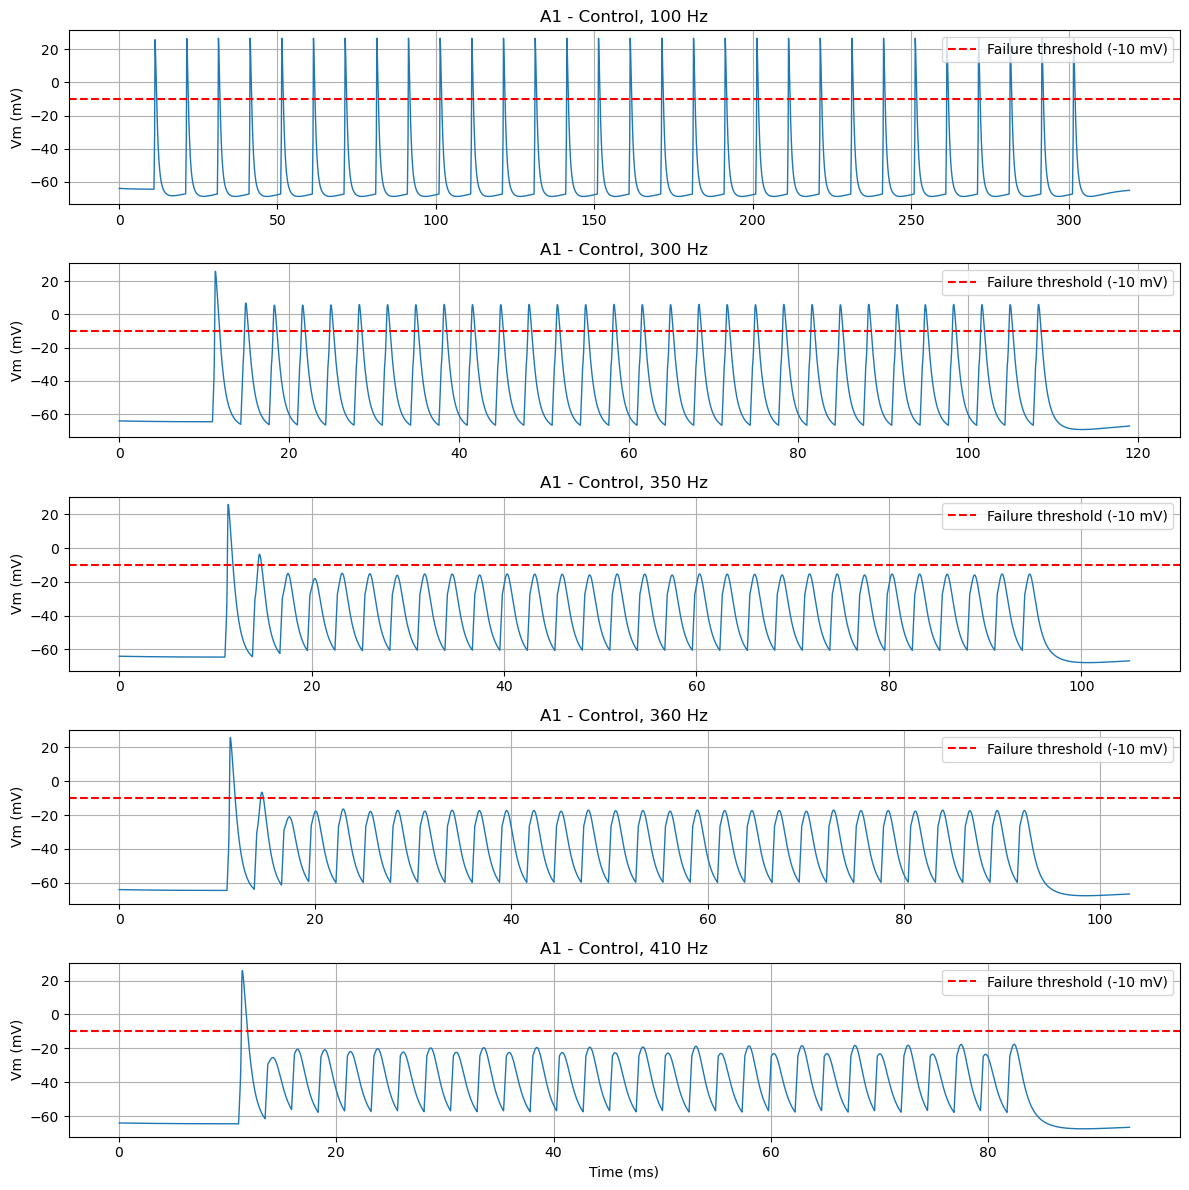


A1 - CONTROL: QUANTITATIVE SUMMARY
Frequency   Successes     Failures    Mean latency    Latency SD
100         30/30          0/30        1.360 ms        0.002 ms
300         30/30          0/30        1.616 ms        0.051 ms
350         2/30          28/30        1.545 ms        0.276 ms
360         2/30          28/30        1.560 ms        0.297 ms
410         1/30          29/30        1.350 ms        0.000 ms


In [16]:

# ============================================================
# A1 - CONTROL CONDITION
# Kv3.1 conductance = 150 nS
# Reproduction of Figure 9 (Macica et al., 2003)
#
# Figure 9a: AP latency vs stimulus number
# Figure 9b: Superimposed action potentials
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import nest

# ------------------------------------------------------------
# 1. Simulation parameters
# ------------------------------------------------------------

dt = 0.01
frequencies = [100, 300, 350, 360, 410]

n_pulses = 30
amplitude = 1400.0       # pA = 1.4 nA
pulse_width = 0.25       # ms
start_time = 10.0        # ms

g_kv3 = 150.0            # nS - Control
threshold = -10.0        # mV - Failure threshold

# Window used to display superimposed action potentials
pre_window = 0.5         # ms before stimulus
post_window = 2.5        # ms after stimulus

# Store all results
results_A1 = {}

# ------------------------------------------------------------
# 2. Run simulations at all frequencies
# ------------------------------------------------------------

for frequency in frequencies:

    print(f"\nRunning A1 at {frequency} Hz...")

    period = 1000.0 / frequency

    # Reset and configure NEST
    nest.ResetKernel()
    nest.SetKernelStatus({"resolution": dt})
    nest.Install(wt_module)

    # Create neuron in control condition
    neuron = nest.Create(
        wt_model,
        1,
        params={"g_Kv3": g_kv3}
    )

    # --------------------------------------------------------
    # 3. Generate current pulse train
    # --------------------------------------------------------

    amplitude_times = []
    amplitude_values = []
    pulse_onsets = []

    for i in range(n_pulses):

        t_on = round((start_time + i * period) / dt) * dt
        t_off = round((start_time + i * period + pulse_width) / dt) * dt

        pulse_onsets.append(t_on)

        amplitude_times.extend([t_on, t_off])
        amplitude_values.extend([amplitude, 0.0])

    stimulus = nest.Create(
        "step_current_generator",
        1,
        params={
            "amplitude_times": amplitude_times,
            "amplitude_values": amplitude_values
        }
    )

    # --------------------------------------------------------
    # 4. Record membrane potential
    # --------------------------------------------------------

    multimeter = nest.Create(
        "multimeter",
        1,
        params={
            "record_from": ["V_m"],
            "interval": dt
        }
    )

    nest.Connect(stimulus, neuron)
    nest.Connect(multimeter, neuron)

    # --------------------------------------------------------
    # 5. Run simulation
    # --------------------------------------------------------

    simulation_time = start_time + n_pulses * period + 10.0
    simulation_time = round(simulation_time / dt) * dt

    nest.Simulate(simulation_time)

    # Extract voltage trace
    events = multimeter.get("events")
    times = events["times"].copy()
    voltage = events["V_m"].copy()

    # --------------------------------------------------------
    # 6. Calculate peak voltage and AP latency
    # --------------------------------------------------------

    response_peaks = []
    latencies = []
    successful_traces = []

    for i, t_on in enumerate(pulse_onsets):

        if i < n_pulses - 1:
            t_next = pulse_onsets[i + 1]
        else:
            t_next = simulation_time

        # Voltage trace during the response interval
        mask = (times >= t_on) & (times < t_next)

        if not np.any(mask):
            response_peaks.append(np.nan)
            latencies.append(np.nan)
            continue

        local_times = times[mask]
        local_voltage = voltage[mask]

        # Find maximum membrane potential
        peak_index = np.argmax(local_voltage)
        peak_voltage = local_voltage[peak_index]
        peak_time = local_times[peak_index]

        response_peaks.append(peak_voltage)

        # Failure if depolarization remains below -10 mV
        if peak_voltage < threshold:

            latencies.append(np.nan)

        else:

            latency = peak_time - t_on
            latencies.append(latency)

            # Extract successful AP waveform aligned to stimulus onset
            trace_mask = (
                (times >= t_on - pre_window) &
                (times <= t_on + post_window)
            )

            relative_times = times[trace_mask] - t_on
            relative_voltage = voltage[trace_mask]

            successful_traces.append(
                (relative_times, relative_voltage)
            )

    response_peaks = np.array(response_peaks)
    latencies = np.array(latencies)

    successes = np.sum(response_peaks >= threshold)
    failures = n_pulses - successes

    # Store results
    results_A1[frequency] = {
        "times": times,
        "voltage": voltage,
        "peaks": response_peaks,
        "latencies": latencies,
        "successes": int(successes),
        "failures": int(failures),
        "traces": successful_traces
    }

    print(f"Successful responses: {successes}/{n_pulses}")
    print(f"Failures: {failures}/{n_pulses}")



# ============================================================
# FIGURE 9a - A1 CONTROL (150 nS)
# Layout matching Macica et al. (2003), Figure 9a
# ============================================================

fig, axes = plt.subplots(
    4, 1,
    figsize=(5, 9),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(hspace=0.55)

for ax, frequency in zip(axes, [300, 350, 360, 410]):

    data = results_A1[frequency]

    stimulus_numbers = np.arange(1, n_pulses + 1)
    latencies = data["latencies"]

    successful = ~np.isnan(latencies)
    failed = np.isnan(latencies)

    # Successful action potentials
    ax.plot(
        stimulus_numbers[successful],
        latencies[successful],
        "ko-",
        markersize=2.5,
        linewidth=0.7
    )

    # Failures indicated by downward arrows
    for stimulus_number in stimulus_numbers[failed]:

        ax.annotate(
            "",
            xy=(stimulus_number, 0.05),
            xytext=(stimulus_number, 0.35),
            arrowprops=dict(
                arrowstyle="->",
                color="black",
                linewidth=0.7
            )
        )

    ax.set_title(f"{frequency} Hz", fontsize=9, pad=3)
    ax.set_xlim(0, n_pulses + 1)
    ax.set_ylim(0, 1.5)

    ax.set_yticks([0, 0.5, 1.0, 1.5])
    ax.set_xticks([0, 10, 20, 30])

    ax.tick_params(labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Stimulus number", fontsize=9)
fig.supylabel("Delay (ms)", fontsize=9)

fig.suptitle(
    "A1 - Control (Kv3.1 = 150 nS)",
    fontsize=11
)

plt.show()

# ------------------------------------------------------------
# 8. Figure 9b - Superimposed action potentials
# Selected frequencies: 100, 350, 360, 410 Hz
# Failures are excluded
# ------------------------------------------------------------

selected_frequencies = [100, 350, 360, 410]

fig, axes = plt.subplots(
    1, 4,
    figsize=(15, 4),
    sharey=True
)

for ax, frequency in zip(axes, selected_frequencies):

    data = results_A1[frequency]

    for relative_times, relative_voltage in data["traces"]:

        ax.plot(
            relative_times,
            relative_voltage,
            linewidth=1
        )

    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

    ax.set_title(f"{frequency} Hz")
    ax.set_xlabel("Time from stimulus (ms)")
    ax.grid()

axes[0].set_ylabel("Membrane potential (mV)")

fig.suptitle(
    "A1 - Figure 9b: Superimposed action potentials",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Additional voltage traces - Vm vs time
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(frequencies), 1,
    figsize=(12, 12)
)

for ax, frequency in zip(axes, frequencies):

    data = results_A1[frequency]

    ax.plot(data["times"], data["voltage"], linewidth=1)

    ax.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Failure threshold (-10 mV)"
    )

    ax.set_title(f"A1 - Control, {frequency} Hz")
    ax.set_ylabel("Vm (mV)")
    ax.grid()
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (ms)")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Quantitative summary
# ------------------------------------------------------------

print("\n==============================================")
print("A1 - CONTROL: QUANTITATIVE SUMMARY")
print("==============================================")

print(
    f"{'Frequency':<12}"
    f"{'Successes':<14}"
    f"{'Failures':<12}"
    f"{'Mean latency':<16}"
    f"{'Latency SD'}"
)

for frequency in frequencies:

    data = results_A1[frequency]
    valid_latencies = data["latencies"][~np.isnan(data["latencies"])]

    if len(valid_latencies) > 0:
        mean_latency = np.mean(valid_latencies)
        std_latency = np.std(valid_latencies, ddof=1) if len(valid_latencies) > 1 else 0.0
        latency_text = f"{mean_latency:.3f} ms"
        std_text = f"{std_latency:.3f} ms"
    else:
        latency_text = "N/A"
        std_text = "N/A"

    print(
        f"{frequency:<12}"
        f"{data['successes']}/{n_pulses:<12}"
        f"{data['failures']}/{n_pulses:<10}"
        f"{latency_text:<16}"
        f"{std_text}"
    )



Running A2 at 100 Hz...

Nov 19 12:30:41 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.01 ms.

Nov 19 12:30:41 Install [Info]: 
    loaded module nestml_e35a44de6d6040ad904717fa6e570e0b_module

Nov 19 12:30:41 NodeManager::prepare_nodes [Info]: 
    Preparing 3 nodes for simulation.

Nov 19 12:30:41 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 3
    Simulation time (ms): 320
    Number of OpenMP threads: 1
    Number of MPI processes: 1

Nov 19 12:30:41 SimulationManager::run [Info]: 
    Simulation finished.
Successful responses: 30/30
Failures: 0/30

Running A2 at 300 Hz...

Nov 19 12:30:41 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.01 ms.

Nov 19 12:30:41 Install [Info]: 
    loaded module nestml_e35a44de6d6040ad904717fa6e570e0b_module

Nov 19 12:30:41 NodeManager::prepare_nodes [Info]: 
    Preparing 3 nodes for simulation.

Nov 19 12:30:41 SimulationManager::start_updating_ 

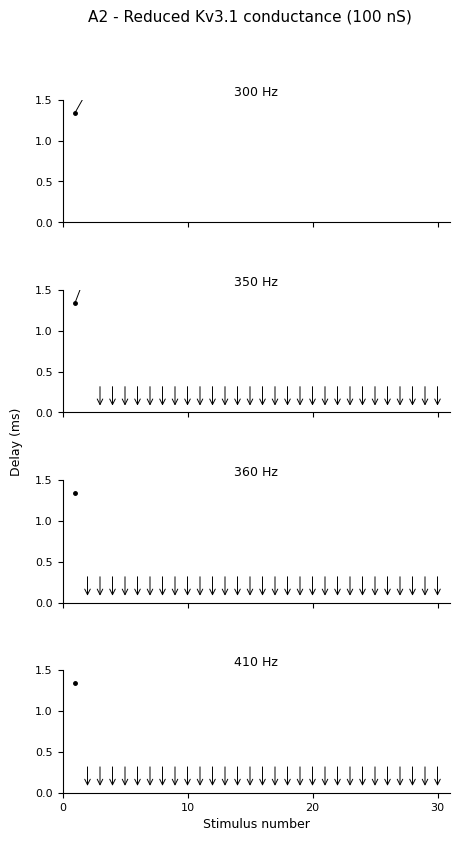

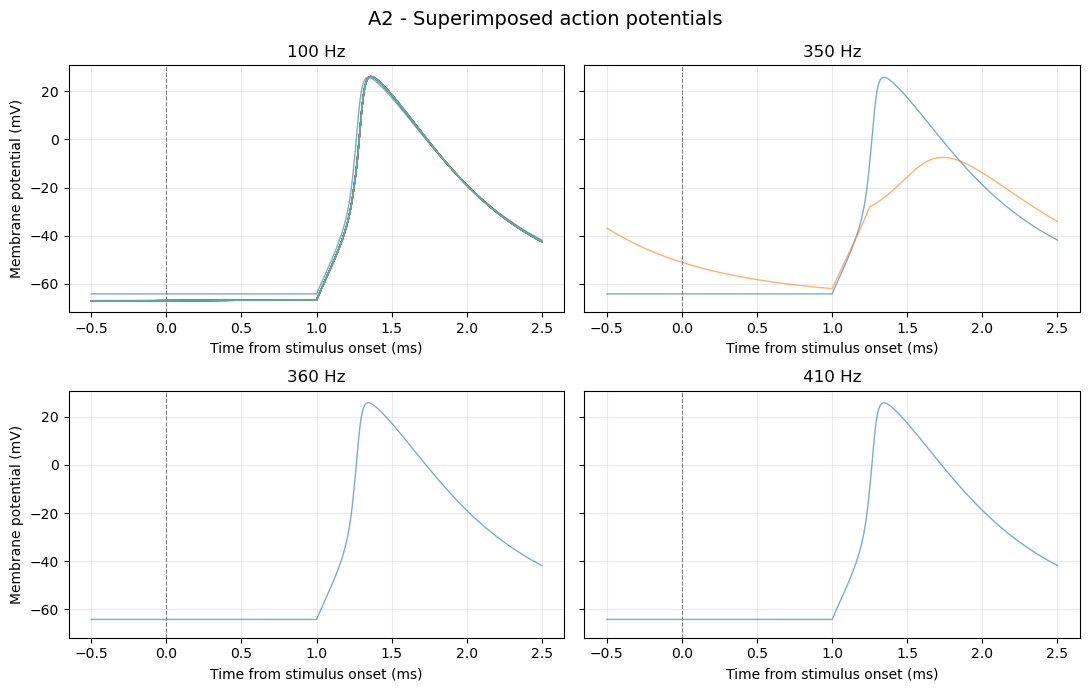

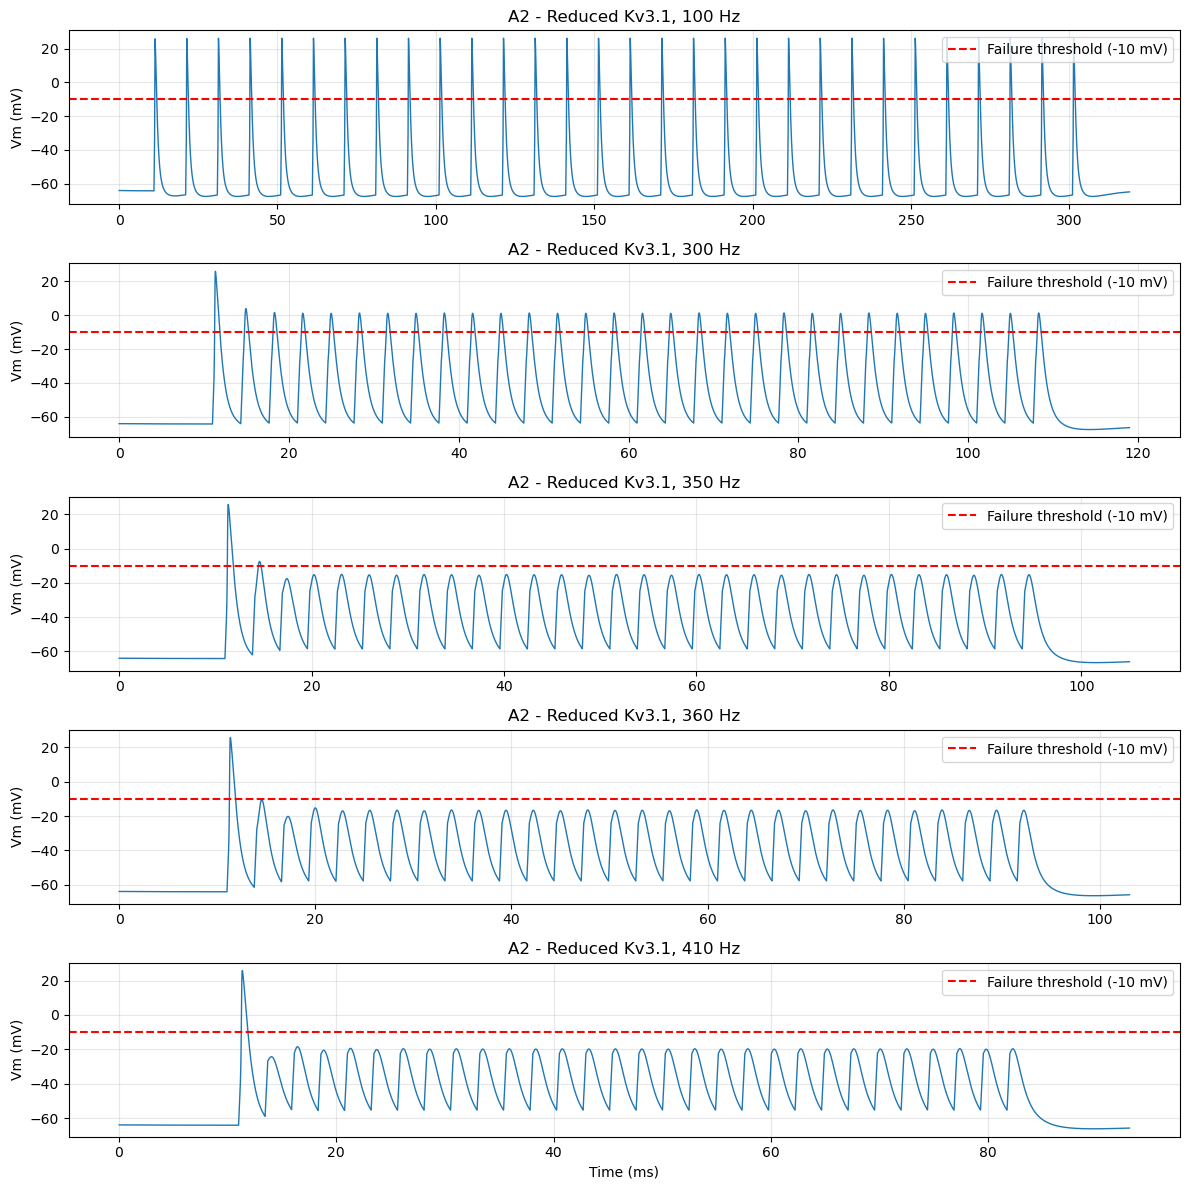


A2 - REDUCED Kv3.1: QUANTITATIVE SUMMARY
Frequency   Successes     Failures    Mean latency   Latency SD
100         30/30          0/30        1.359          0.004
300         30/30          0/30        1.629          0.055
350         2/30          28/30        1.540          0.283
360         1/30          29/30        1.340          0.000
410         1/30          29/30        1.340          0.000


In [17]:

# ============================================================
# A2 - REDUCED Kv3.1 CONDUCTANCE
# Kv3.1 conductance = 100 nS
# Frequencies: 100, 300, 350, 360, 410 Hz
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import nest

# ------------------------------------------------------------
# 1. Simulation parameters
# ------------------------------------------------------------

dt = 0.01
frequencies = [100, 300, 350, 360, 410]

n_pulses = 30
amplitude = 1400.0       # pA = 1.4 nA
pulse_width = 0.25       # ms
start_time = 10.0        # ms

g_kv3 = 100.0            # nS - Reduced Kv3.1
threshold = -10.0        # mV - Failure threshold

pre_window = 0.5         # ms before stimulus
post_window = 2.5        # ms after stimulus

# Store results
results_A2 = {}

# ------------------------------------------------------------
# 2. Run simulations at all frequencies
# ------------------------------------------------------------

for frequency in frequencies:

    print(f"\nRunning A2 at {frequency} Hz...")

    period = 1000.0 / frequency

    # Reset and configure NEST
    nest.ResetKernel()
    nest.SetKernelStatus({"resolution": dt})
    nest.Install(wt_module)

    # Create neuron with reduced Kv3.1 conductance
    neuron = nest.Create(
        wt_model,
        1,
        params={"g_Kv3": g_kv3}
    )

    # --------------------------------------------------------
    # 3. Generate current pulse train
    # --------------------------------------------------------

    amplitude_times = []
    amplitude_values = []
    pulse_onsets = []

    for i in range(n_pulses):

        t_on = round((start_time + i * period) / dt) * dt
        t_off = round((start_time + i * period + pulse_width) / dt) * dt

        pulse_onsets.append(t_on)

        amplitude_times.extend([t_on, t_off])
        amplitude_values.extend([amplitude, 0.0])

    stimulus = nest.Create(
        "step_current_generator",
        1,
        params={
            "amplitude_times": amplitude_times,
            "amplitude_values": amplitude_values
        }
    )

    # --------------------------------------------------------
    # 4. Record membrane potential
    # --------------------------------------------------------

    multimeter = nest.Create(
        "multimeter",
        1,
        params={
            "record_from": ["V_m"],
            "interval": dt
        }
    )

    nest.Connect(stimulus, neuron)
    nest.Connect(multimeter, neuron)

    # --------------------------------------------------------
    # 5. Run simulation
    # --------------------------------------------------------

    simulation_time = start_time + n_pulses * period + 10.0
    simulation_time = round(simulation_time / dt) * dt

    nest.Simulate(simulation_time)

    # --------------------------------------------------------
    # 6. Extract voltage trace
    # --------------------------------------------------------

    events = multimeter.get("events")

    times = events["times"].copy()
    voltage = events["V_m"].copy()

    # --------------------------------------------------------
    # 7. Calculate peak voltage and AP latency
    # --------------------------------------------------------

    response_peaks = []
    latencies = []
    successful_traces = []

    for i, t_on in enumerate(pulse_onsets):

        if i < n_pulses - 1:
            t_next = pulse_onsets[i + 1]
        else:
            t_next = simulation_time

        mask = (times >= t_on) & (times < t_next)

        if not np.any(mask):
            response_peaks.append(np.nan)
            latencies.append(np.nan)
            continue

        local_times = times[mask]
        local_voltage = voltage[mask]

        # Find maximum membrane potential
        peak_index = np.argmax(local_voltage)
        peak_voltage = local_voltage[peak_index]
        peak_time = local_times[peak_index]

        response_peaks.append(peak_voltage)

        # Classify successful responses and failures
        if peak_voltage < threshold:

            latencies.append(np.nan)

        else:

            latency = peak_time - t_on
            latencies.append(latency)

            # Extract AP waveform aligned to stimulus onset
            trace_mask = (
                (times >= t_on - pre_window) &
                (times <= t_on + post_window)
            )

            relative_times = times[trace_mask] - t_on
            relative_voltage = voltage[trace_mask]

            successful_traces.append(
                (relative_times, relative_voltage)
            )

    response_peaks = np.array(response_peaks)
    latencies = np.array(latencies)

    successes = np.sum(response_peaks >= threshold)
    failures = n_pulses - successes

    # Store results
    results_A2[frequency] = {
        "times": times,
        "voltage": voltage,
        "peaks": response_peaks,
        "latencies": latencies,
        "successes": int(successes),
        "failures": int(failures),
        "traces": successful_traces
    }

    print(f"Successful responses: {successes}/{n_pulses}")
    print(f"Failures: {failures}/{n_pulses}")

# ------------------------------------------------------------
# 8. FIGURE 9a - AP latency vs stimulus number
# Layout matching the original article
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 1,
    figsize=(5, 9),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(hspace=0.55)

for ax, frequency in zip(axes, [300, 350, 360, 410]):

    data = results_A2[frequency]

    stimulus_numbers = np.arange(1, n_pulses + 1)
    latencies = data["latencies"]

    successful = ~np.isnan(latencies)
    failed = np.isnan(latencies)

    # Successful action potentials
    ax.plot(
        stimulus_numbers[successful],
        latencies[successful],
        "ko-",
        markersize=2.5,
        linewidth=0.7
    )

    # Failures indicated by downward arrows
    for stimulus_number in stimulus_numbers[failed]:

        ax.annotate(
            "",
            xy=(stimulus_number, 0.05),
            xytext=(stimulus_number, 0.35),
            arrowprops=dict(
                arrowstyle="->",
                color="black",
                linewidth=0.7
            )
        )

    ax.set_title(f"{frequency} Hz", fontsize=9, pad=3)
    ax.set_xlim(0, n_pulses + 1)
    ax.set_ylim(0, 1.5)

    ax.set_yticks([0, 0.5, 1.0, 1.5])
    ax.set_xticks([0, 10, 20, 30])

    ax.tick_params(labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Stimulus number", fontsize=9)
fig.supylabel("Delay (ms)", fontsize=9)

fig.suptitle(
    "A2 - Reduced Kv3.1 conductance (100 nS)",
    fontsize=11
)

plt.show()

# ------------------------------------------------------------
# 9. FIGURE 9b - Superimposed action potentials
# Frequencies: 100, 350, 360, 410 Hz
# Failures excluded
# ------------------------------------------------------------

selected_frequencies = [100, 350, 360, 410]

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharey=True
)

axes = axes.flatten()

for ax, frequency in zip(axes, selected_frequencies):

    data = results_A2[frequency]

    for relative_times, relative_voltage in data["traces"]:

        ax.plot(
            relative_times,
            relative_voltage,
            linewidth=1,
            alpha=0.6
        )

    ax.axvline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(f"{frequency} Hz")
    ax.set_xlabel("Time from stimulus onset (ms)")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Membrane potential (mV)")
axes[2].set_ylabel("Membrane potential (mV)")

fig.suptitle(
    "A2 - Superimposed action potentials",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Vm vs time - all frequencies
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(frequencies), 1,
    figsize=(12, 12)
)

for ax, frequency in zip(axes, frequencies):

    data = results_A2[frequency]

    ax.plot(
        data["times"],
        data["voltage"],
        linewidth=1
    )

    ax.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Failure threshold (-10 mV)"
    )

    ax.set_title(f"A2 - Reduced Kv3.1, {frequency} Hz")
    ax.set_ylabel("Vm (mV)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (ms)")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Quantitative summary
# ------------------------------------------------------------

print("\n==============================================")
print("A2 - REDUCED Kv3.1: QUANTITATIVE SUMMARY")
print("==============================================")

print(
    f"{'Frequency':<12}"
    f"{'Successes':<14}"
    f"{'Failures':<12}"
    f"{'Mean latency':<15}"
    f"{'Latency SD'}"
)

for frequency in frequencies:

    data = results_A2[frequency]

    valid_latencies = data["latencies"][
        ~np.isnan(data["latencies"])
    ]

    if len(valid_latencies) > 0:

        mean_latency = np.mean(valid_latencies)

        std_latency = (
            np.std(valid_latencies, ddof=1)
            if len(valid_latencies) > 1
            else 0.0
        )

        mean_text = f"{mean_latency:.3f}"
        std_text = f"{std_latency:.3f}"

    else:

        mean_text = "N/A"
        std_text = "N/A"

    print(
        f"{frequency:<12}"
        f"{data['successes']}/{n_pulses:<12}"
        f"{data['failures']}/{n_pulses:<10}"
        f"{mean_text:<15}"
        f"{std_text}"
    )



Nov 20 11:34:31 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.01 ms.

Nov 20 11:34:31 Install [Info]: 
    loaded module nestml_57233ee08c6948bda14acd9ba89d6131_module

Nov 20 11:34:31 NodeManager::prepare_nodes [Info]: 
    Preparing 3 nodes for simulation.

Nov 20 11:34:31 SimulationManager::run [Warning]: 
    The requested simulation time is not an integer multiple of the minimal 
    delay in the network. This may result in inconsistent results under the 
    following conditions: (i) A network contains more than one source of 
    randomness, e.g., two different poisson_generators, and (ii) Simulate is 
    called repeatedly with simulation times that are not multiples of the 
    minimal delay.

Nov 20 11:34:31 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 3
    Simulation time (ms): 105.71
    Number of OpenMP threads: 1
    Number of MPI processes: 1

Nov 20 11:34:31 SimulationManager::run [Info]: 
    Simulation

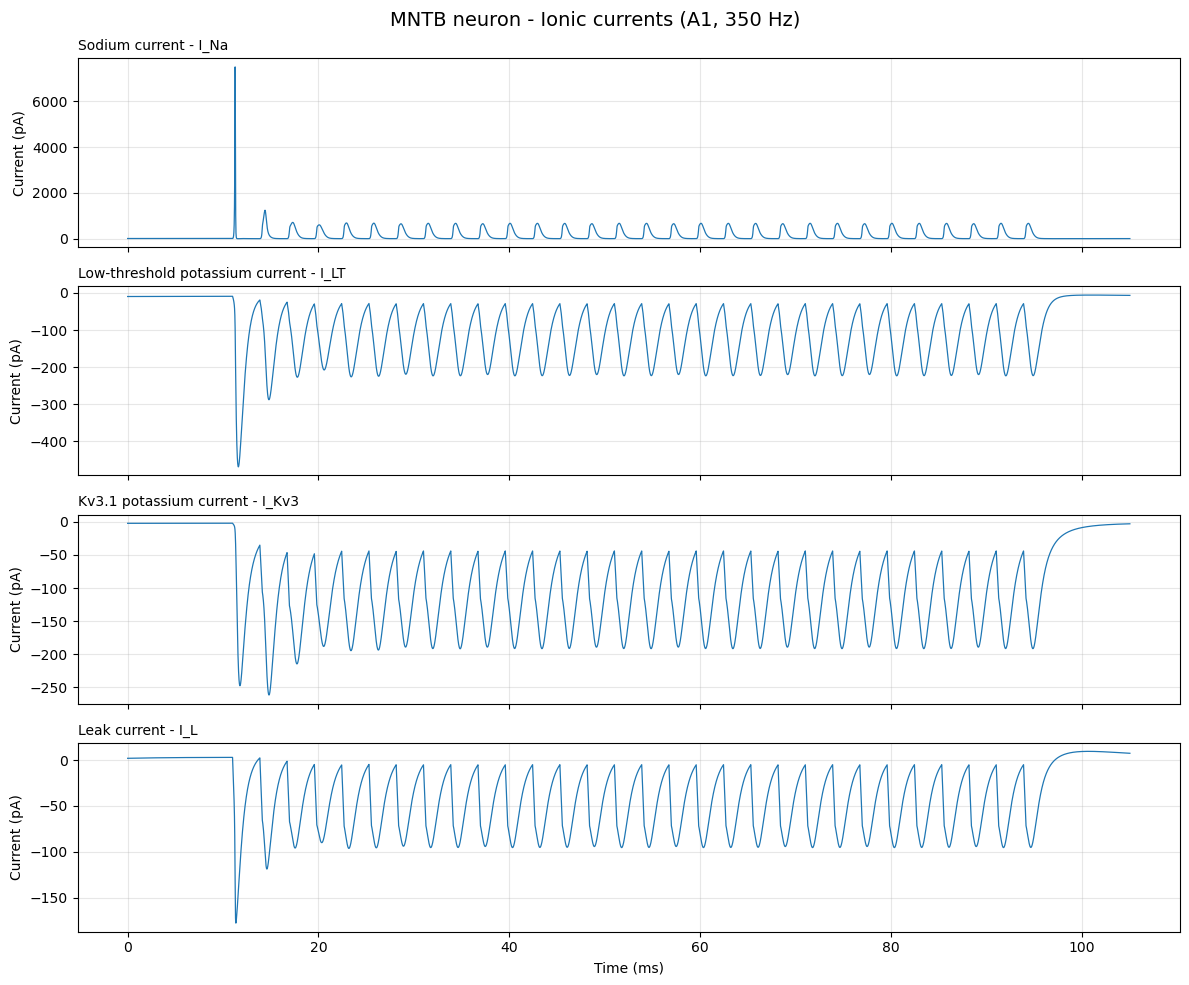

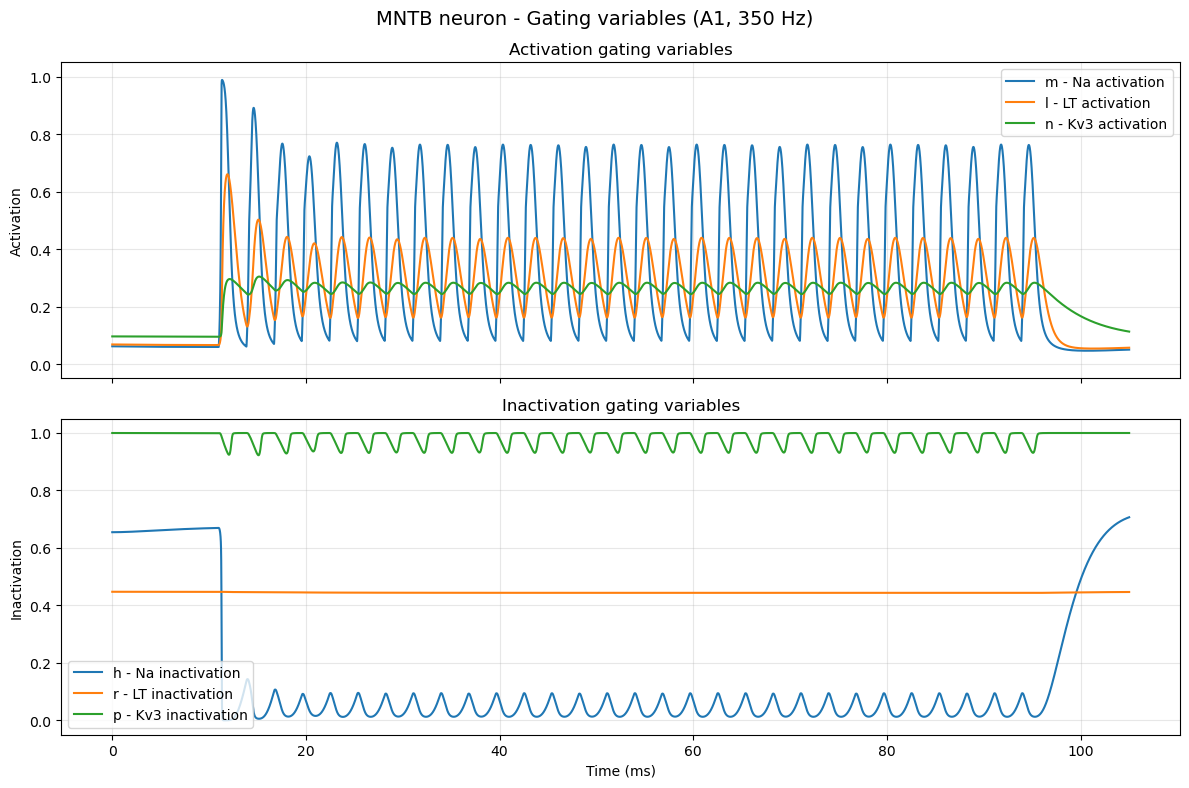


IONIC CURRENT RANGES
I_Na: min = 0.470 pA, max = 7502.175 pA
I_LT: min = -468.441 pA, max = -5.878 pA
I_Kv3: min = -261.590 pA, max = -1.987 pA
I_L: min = -177.779 pA, max = 9.576 pA

GATING VARIABLE RANGES
m: min = 0.04640, max = 0.98868
h: min = 0.00003, max = 0.70676
l: min = 0.05389, max = 0.66066
r: min = 0.44365, max = 0.44752
n: min = 0.09490, max = 0.30443
p: min = 0.92258, max = 0.99998


In [12]:

# ============================================================
# MNTB MODEL VALIDATION
# Ionic currents and gating variables
# A1 - Control condition (g_Kv3 = 150 nS)
# Stimulation frequency = 350 Hz
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import nest

# ------------------------------------------------------------
# 1. Simulation parameters
# ------------------------------------------------------------

dt = 0.01
frequency = 350
n_pulses = 30

amplitude = 1400.0       # pA
pulse_width = 0.25       # ms
start_time = 10.0        # ms

g_Na = 500.0             # nS
g_LT = 20.0              # nS
g_Kv3 = 150.0            # nS - A1 control
g_L = 2.0                # nS

E_Na = 50.0              # mV
E_K = -80.0              # mV
E_L = -63.0              # mV

period = 1000.0 / frequency

# ------------------------------------------------------------
# 2. Reset kernel and load NESTML model
# ------------------------------------------------------------

nest.ResetKernel()
nest.SetKernelStatus({"resolution": dt})
nest.Install(wt_module)

# Create neuron
neuron = nest.Create(
    wt_model,
    1,
    params={"g_Kv3": g_Kv3}
)

# ------------------------------------------------------------
# 3. Generate stimulus
# ------------------------------------------------------------

amplitude_times = []
amplitude_values = []

for i in range(n_pulses):

    t_on = round((start_time + i * period) / dt) * dt
    t_off = round((start_time + i * period + pulse_width) / dt) * dt

    amplitude_times.extend([t_on, t_off])
    amplitude_values.extend([amplitude, 0.0])

stimulus = nest.Create(
    "step_current_generator",
    1,
    params={
        "amplitude_times": amplitude_times,
        "amplitude_values": amplitude_values
    }
)

nest.Connect(stimulus, neuron)

# ------------------------------------------------------------
# 4. Record membrane potential and gating variables
# ------------------------------------------------------------

recordables = [
    "V_m",
    "Act_m",
    "Inact_h",
    "Act_l",
    "Inact_r",
    "Act_n",
    "Inact_p"
]

multimeter = nest.Create(
    "multimeter",
    1,
    params={
        "record_from": recordables,
        "interval": dt
    }
)

nest.Connect(multimeter, neuron)

# ------------------------------------------------------------
# 5. Run simulation
# ------------------------------------------------------------

simulation_time = start_time + n_pulses * period + 10.0
simulation_time = round(simulation_time / dt) * dt

nest.Simulate(simulation_time)

# ------------------------------------------------------------
# 6. Extract recorded variables
# ------------------------------------------------------------

events = multimeter.get("events")

times = events["times"]
V_m = events["V_m"]

# Sodium gates
m = events["Act_m"]
h = events["Inact_h"]

# Low-threshold potassium gates
l = events["Act_l"]
r = events["Inact_r"]

# Kv3 gates
n = events["Act_n"]
p = events["Inact_p"]

# ------------------------------------------------------------
# 7. Calculate ionic currents
# Using the exact equations implemented in NESTML
# nS * mV = pA
# ------------------------------------------------------------

I_Na = g_Na * (m**3) * h * (E_Na - V_m)

I_LT = g_LT * l * r * (E_K - V_m)

I_Kv3 = g_Kv3 * (n**3) * (0.8 + 0.2 * p) * (E_K - V_m)

I_L = g_L * (E_L - V_m)

# ------------------------------------------------------------
# 8. FIGURE 1 - Ionic currents
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 10),
    sharex=True
)

currents = [
    (I_Na, "Sodium current - I_Na"),
    (I_LT, "Low-threshold potassium current - I_LT"),
    (I_Kv3, "Kv3.1 potassium current - I_Kv3"),
    (I_L, "Leak current - I_L")
]

for ax, (current, label) in zip(axes, currents):

    ax.plot(times, current, linewidth=0.9)
    ax.set_ylabel("Current (pA)")
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (ms)")

fig.suptitle(
    "MNTB neuron - Ionic currents (A1, 350 Hz)",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. FIGURE 2 - Gating variables
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# Activation variables
axes[0].plot(times, m, label="m - Na activation")
axes[0].plot(times, l, label="l - LT activation")
axes[0].plot(times, n, label="n - Kv3 activation")

axes[0].set_ylabel("Activation")
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_title("Activation gating variables")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Inactivation variables
axes[1].plot(times, h, label="h - Na inactivation")
axes[1].plot(times, r, label="r - LT inactivation")
axes[1].plot(times, p, label="p - Kv3 inactivation")

axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Inactivation")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Inactivation gating variables")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "MNTB neuron - Gating variables (A1, 350 Hz)",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Print current and gating ranges
# ------------------------------------------------------------

print("\nIONIC CURRENT RANGES")

for name, current in [
    ("I_Na", I_Na),
    ("I_LT", I_LT),
    ("I_Kv3", I_Kv3),
    ("I_L", I_L)
]:
    print(
        f"{name}: min = {np.min(current):.3f} pA, "
        f"max = {np.max(current):.3f} pA"
    )

print("\nGATING VARIABLE RANGES")

for name, gate in [
    ("m", m), ("h", h),
    ("l", l), ("r", r),
    ("n", n), ("p", p)
]:
    print(
        f"{name}: min = {np.min(gate):.5f}, "
        f"max = {np.max(gate):.5f}"
    )
